In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/robinaz/fin20005data/volatility.csv
/kaggle/input/datasets/robinaz/fin20005data/us_equities.csv
/kaggle/input/datasets/robinaz/fin20005data/crypto.csv
/kaggle/input/datasets/robinaz/fin20005data/equities.csv
/kaggle/input/datasets/robinaz/fin20005data/fixed_income.csv
/kaggle/input/datasets/robinaz/fin20005data/asset_Info.csv
/kaggle/input/datasets/robinaz/fin20005data/commodities.csv
/kaggle/input/datasets/robinaz/fin20005data/fx.csv


# Step 1: Introduction to the data

# Confidence Intervals for the Mean: UK Gilt Returns

**FIN-20005 Financial Analysis with Bloomberg**

## Purpose of this notebook

Investors often ask: *what return can I expect from holding UK government bonds (gilts)?*
We can never know the true expected return. We only observe a limited history of returns.
A **confidence interval** tells us how precisely that history pins down the true average.

In this notebook you will:

1. Load ~10 years of daily UK gilt index data and plot it as a time series.
2. Convert prices into daily log returns.
3. Produce a descriptive-statistics table (the same one Excel's *Data Analysis → Descriptive Statistics* gives you).
4. Build a 95% confidence interval for the mean daily return, by hand and with SciPy.
5. Interpret the interval precisely, and translate it into annual terms.
6. See how the interval changes with the confidence level, with the sample size, and with t versus Z.

## The data

| Item | Detail |
|---|---|
| File | `fixed_income.csv` |
| Series | `GILTS`: a UK government bond (gilt) index, downloaded from Bloomberg |
| Frequency | Daily closing values (trading days only) |
| Period | January 2015 onwards (about 10 years) |

Gilts are bonds issued by the UK government. When interest rates rise, existing bond prices fall,
so the gilt index moves *inversely* to UK interest rates. Two episodes to look for:

* **March 2020** – COVID-19 market turmoil.
* **September–October 2022** – the "mini-budget" gilt crisis, when gilt prices collapsed and the Bank of England intervened.

# Step 2. Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats

# Step 3: Load the gilt data

In [3]:
gilts = pd.read_csv("/kaggle/input/datasets/robinaz/fin20005data/fixed_income.csv",
                    parse_dates=["Date"],      # read the Date column as dates, not text
                    index_col="Date")          # use the dates as the row index → time-series plots
print(gilts.shape)
print("First date:", gilts.index.min().date(), "  Last date:", gilts.index.max().date())
gilts.head()

(2778, 1)
First date: 2015-01-02   Last date: 2025-12-31


,GILTS
Date,
2015-01-02,9.6395
2015-01-05,9.6947
2015-01-06,9.7673
2015-01-07,9.7489
2015-01-08,9.7227


# Step 4: Plot the gilt index (time series)

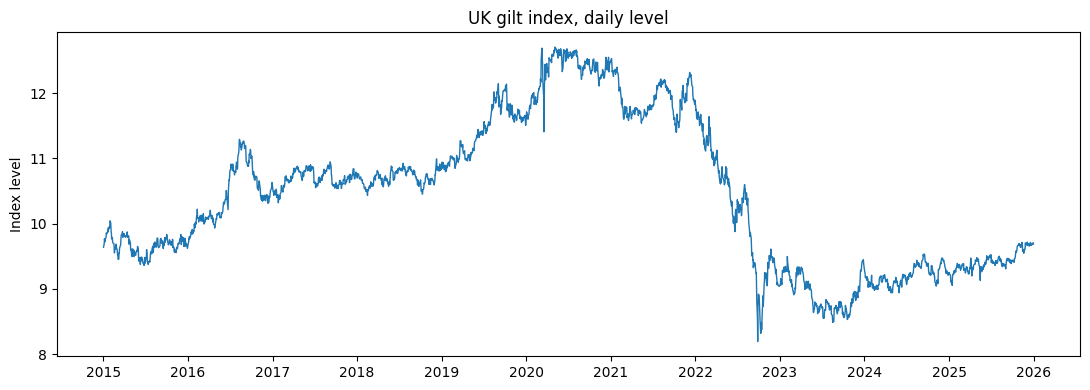

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))                    # create a blank chart
ax.plot(gilts.index, gilts["GILTS"], lw=1)                 # index level against date
ax.set_title("UK gilt index, daily level")
ax.set_ylabel("Index level")
ax.xaxis.set_major_locator(mdates.YearLocator())           # one tick per year
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))   # show the year only
plt.tight_layout()
plt.show()

# Step 5: Calculate daily log returns

$$r_t = 100 \times \ln\left(\frac{P_t}{P_{t-1}}\right)$$

We build the confidence interval on **returns**, not prices.
Prices trend over time (they are non-stationary), so "the mean price" has no stable meaning.
Returns fluctuate around a fairly stable average, which is the quantity we want to estimate.

In [5]:
gilts["Return"] = np.log(gilts["GILTS"]).diff() * 100   # log return, in %
returns = gilts["Return"].dropna()                       # first day has no return → drop it

gilts.head(6)        # the first row's return is NaN: there is no previous price to compare with

,GILTS,Return
Date,,
2015-01-02,9.6395,NaN
2015-01-05,9.6947,0.571010
2015-01-06,9.7673,0.746073
2015-01-07,9.7489,-0.188561
2015-01-08,9.7227,-0.269110
2015-01-09,9.7653,0.437193


In [6]:
returns.head(10)     # first 10 daily returns, with their dates

Date
2015-01-05    0.571010
2015-01-06    0.746073
2015-01-07   -0.188561
2015-01-08   -0.269110
2015-01-09    0.437193
2015-01-12    0.139172
2015-01-13    0.118552
2015-01-14    0.670846
2015-01-15   -0.108618
2015-01-16   -0.029459
Name: Return, dtype: float64

# Step 6: Plot daily returns (time series)

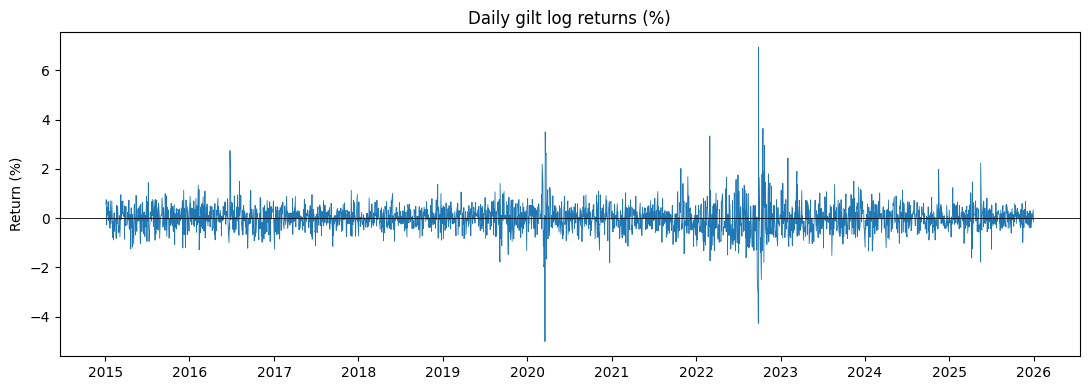

In [7]:
fig, ax = plt.subplots(figsize=(11, 4))                    # create a blank chart
ax.plot(returns.index, returns, lw=0.6)                    # daily return against date
ax.axhline(0, color="black", lw=0.6)                       # zero line
ax.set_title("Daily gilt log returns (%)")
ax.set_ylabel("Return (%)")
ax.xaxis.set_major_locator(mdates.YearLocator())           # one tick per year
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))   # show the year only
plt.tight_layout()
plt.show()

# Step 7: Sample or population?

**Sample or population?** Our 10 years of daily returns are a **sample**. The population is all returns the gilt market could generate, past and future, and its true mean μ is unknown. We use the sample mean x̄ and a confidence interval to estimate μ. (If we only wanted the average return for 2015–2025 itself, the data would be the whole population and no confidence interval would be needed.)

# Step 8: Descriptive statistics

In [8]:
n    = len(returns)               # sample size: number of daily returns
xbar = returns.mean()             # sample mean x̄
s    = returns.std(ddof=1)        # sample standard deviation s (estimate of σ)
se   = s / np.sqrt(n)             # standard error of the mean = s / √n
t_crit = stats.t.ppf(0.975, n - 1)   # t critical value for 95%, df = n − 1
me   = t_crit * se                # margin of error (Excel calls this "Confidence Level(95.0%)")

desc = pd.Series({
    "Mean":                      xbar,
    "Standard Error":            se,
    "Median":                    returns.median(),
    "Mode":                      returns.round(4).mode().iloc[0],   # not meaningful for continuous data (see note)
    "Standard Deviation":        s,
    "Sample Variance":           returns.var(ddof=1),
    "Kurtosis (excess)":         returns.kurt(),     # same formula as Excel KURT()
    "Skewness":                  returns.skew(),     # same formula as Excel SKEW()
    "Range":                     returns.max() - returns.min(),
    "Minimum":                   returns.min(),
    "Maximum":                   returns.max(),
    "Sum":                       returns.sum(),
    "Count":                     n,
    "Confidence Level(95.0%)":   me,
    "Upper CI (95%)":            xbar + me,
    "Lower CI (95%)":            xbar - me,
    "Width of CI":               2 * me,
}, name="GILTS daily log return (%)")

desc.to_frame().style.format("{:.6f}")

,GILTS daily log return (%)
Mean,0.000184
Standard Error,0.010708
Median,0.000000
Mode,0.000000
Standard Deviation,0.564270
Sample Variance,0.318400
Kurtosis (excess),14.513236
Skewness,0.576287
Range,11.956336
Minimum,-5.013120


# Step 9: 95% confidence interval (σ unknown, t distribution)


$$\bar{x} \pm t_{0.025,\,n-1} \times \frac{s}{\sqrt{n}}$$

In [10]:
conf  = 0.95                          # confidence level
alpha = 1 - conf                      # α = 0.05, both tails together
df    = n - 1                         # degrees of freedom

t_crit = stats.t.ppf(1 - alpha/2, df) # t critical value: look up 0.975 in the t-table
me     = t_crit * se                  # margin of error = critical value × standard error
lower  = xbar - me                    # lower end of the interval
upper  = xbar + me                    # upper end of the interval

print(f"t critical value = {t_crit:.4f}")
print(f"Margin of error  = {me:.4f}%")
print(f"95% CI           = ({lower:.4f}%, {upper:.4f}%)")

t critical value = 1.9608
Margin of error  = 0.0210%
95% CI           = (-0.0208%, 0.0212%)


In [11]:
stats.t.interval(conf, df, loc=xbar, scale=se)   # same interval using SciPy's built-in function

(np.float64(-0.020811920834976804), np.float64(0.021180063457206657))

**Interpretation**

* **t critical value = 1.9608**: for 95% confidence with n − 1 = 2,776 degrees of freedom, we go 1.96 standard errors either side of the sample mean. With this many observations, t is almost the same as Z (1.96).
* **Margin of error = 0.0210%**: our estimate of the mean daily return (x̄ ≈ 0.0002%) could be out by up to about ±0.021 percentage points.
* **95% CI = (−0.0208%, 0.0212%)**: we are 95% confident that the true mean daily return on gilts lies between −0.0208% and +0.0212%. Because the interval includes 0, there is no evidence that the average gilt return differs from zero.

In [9]:
print(f"Standard error   = {se:.4f}%")

Standard error   = 0.0107%


# Step 10: Calculate the confidence interval by hand


Use the values from the output above: x̄ = 0.0002%, s = 0.5643%, n = 2777.

**Step 1: Standard error**
$$SE = \frac{s}{\sqrt{n}} = \frac{0.5643}{\sqrt{2777}} = \frac{0.5643}{52.70} = 0.0107\%$$

**Step 2: Critical value** (from the t-table, 95% two-tailed, df = n − 1 = 2776)
$$t_{0.025,\,2776} \approx 1.96$$

**Step 3: Margin of error**
$$ME = t \times SE = 1.96 \times 0.0107 = 0.0210\%$$

**Step 4: Lower and upper limits**
$$\text{Lower} = \bar{x} - ME = 0.0002 - 0.0210 = -0.0208\%$$
$$\text{Upper} = \bar{x} + ME = 0.0002 + 0.0210 = 0.0212\%$$

Now check your answers with the code below.

**Step 2: Find the t critical value from the t-table**

1. **Confidence level = 95%**, so α = 1 − 0.95 = 0.05.
2. The interval is **two-tailed**, so split α between the two tails: α/2 = 0.025 in each tail.
   → Use the column headed **0.025** (upper-tail probability).
3. **Degrees of freedom** = n − 1 = 2777 − 1 = **2776**.
   → Most tables stop at df = 120 or 1000, then give a final **∞** row. For df this large, use the **∞** row.
4. Read where the row and column meet: **t ≈ 1.960**.

| df \ upper-tail prob. | 0.10 | 0.05 | **0.025** | 0.01 | 0.005 |
|---|---|---|---|---|---|
| 10  | 1.372 | 1.812 | 2.228 | 2.764 | 3.169 |
| 20  | 1.325 | 1.725 | 2.086 | 2.528 | 2.845 |
| 30  | 1.310 | 1.697 | 2.042 | 2.457 | 2.750 |
| 60  | 1.296 | 1.671 | 2.000 | 2.390 | 2.660 |
| 120 | 1.289 | 1.658 | 1.980 | 2.358 | 2.617 |
| **∞** | 1.282 | 1.645 | **1.960** | 2.326 | 2.576 |

Notice that as df increases, the t value gets smaller and approaches the Z value of 1.96. With 2,776 df, t and Z are practically the same.
Python gives the exact value: `stats.t.ppf(0.975, 2776)` = 1.9608.

# Step 11: Compare t and Z intervals


**When do we use each?**

* **Z** interval: σ is **known**. Use $\bar{x} \pm z \times \sigma/\sqrt{n}$.
* **t** interval: σ is **unknown** and estimated by *s*. Use $\bar{x} \pm t \times s/\sqrt{n}$.

In practice σ is almost never known. To create a "σ known" example, we *pretend* the full-sample SD is the true σ,
and build both intervals for the most recent year (n = 252).
(Strictly, this "σ" is itself estimated from data that includes the sample, so this is a teaching device, not a real σ-known situation.)

In [16]:
sigma = returns.std(ddof=1)                 # full-sample SD, treated as "known" σ

sample = returns.iloc[-252:]                # most recent year: the sample
n_s    = len(sample)
xbar_s = sample.mean()
s_s    = sample.std(ddof=1)                 # this year's own SD

z_crit   = stats.norm.ppf(0.975)            # 1.960
t_crit_s = stats.t.ppf(0.975, n_s - 1)      # t with 251 df

me_z = z_crit * sigma / np.sqrt(n_s)        # Z: uses σ
me_t = t_crit_s * s_s / np.sqrt(n_s)        # t: uses s

comp = pd.DataFrame({
    "Critical value":      [z_crit, t_crit_s],
    "SD used (%)":         [sigma, s_s],
    "Margin of error (%)": [me_z, me_t],
    "Lower (%)":           [xbar_s - me_z, xbar_s - me_t],
    "Upper (%)":           [xbar_s + me_z, xbar_s + me_t],
}, index=["Z (σ known = full-sample SD)", "t (σ unknown, uses s)"])
comp.round(4)

,Critical value,SD used (%),Margin of error (%),Lower (%),Upper (%)
Z (σ known = full-sample SD),1.9600,0.5643,0.0697,-0.0513,0.0880
"t (σ unknown, uses s)",1.9695,0.4202,0.0521,-0.0338,0.0705


**Why might the Z interval come out *wider* than the t interval here?**
You may have learned that t intervals are always wider than Z intervals. That is only true when **both use the same standard deviation**.

* The critical values are almost identical (1.960 vs about 1.969). With n = 252, the t distribution is very close to the normal.
* The difference comes from the **standard deviation**: the full-sample σ includes turbulent years such as 2020 and 2022, while the last year's *s* may be lower (or higher). The interval width follows the SD.

**Where t versus Z really matters is in small samples.** Compare the critical values:

In [17]:
for k in [5, 10, 21, 63, 252, 2500]:
    print(f"n = {k:5d}:  t = {stats.t.ppf(0.975, k-1):.3f}   vs   Z = {stats.norm.ppf(0.975):.3f}")
# With n = 5 the t value is about 2.78: much wider than Z. By n ≈ 250 the difference is negligible.

n =     5:  t = 2.776   vs   Z = 1.960
n =    10:  t = 2.262   vs   Z = 1.960
n =    21:  t = 2.086   vs   Z = 1.960
n =    63:  t = 1.999   vs   Z = 1.960
n =   252:  t = 1.969   vs   Z = 1.960
n =  2500:  t = 1.961   vs   Z = 1.960


**Interpretation:** In small samples the t critical value is larger than Z, giving a wider interval to allow for the extra uncertainty from estimating σ with s. As n increases, t converges to Z = 1.96.

# Step 12: Different confidence levels (90%, 95%, 99%)

In [18]:
rows = []                                              # empty list to store results
for c in [0.90, 0.95, 0.99]:                           # loop over three confidence levels
    t_c = stats.t.ppf(1 - (1 - c)/2, n - 1)            # critical value for this level
    m   = t_c * se                                     # margin of error
    rows.append([f"{c:.0%}", round(t_c, 3), round(m, 4),
                 round(xbar - m, 4), round(xbar + m, 4)])   # save the results

pd.DataFrame(rows, columns=["Confidence", "t critical",
                            "Margin of error", "Lower", "Upper"])   # show as a table
# Higher confidence → bigger critical value → wider interval.

,Confidence,t critical,Margin of error,Lower,Upper
0,90%,1.645,0.0176,-0.0174,0.0178
1,95%,1.961,0.0210,-0.0208,0.0212
2,99%,2.578,0.0276,-0.0274,0.0278


# Step 13: Effect of sample size

In [14]:
windows = {"1 month": 21, "3 months": 63, "1 year": 252,
           "5 years": 1260, "Full sample": n}          # trading days in each window
rows = []
for label, k in windows.items():                       # loop over each window
    r    = returns.iloc[-k:]                           # most recent k days
    se_k = r.std(ddof=1) / np.sqrt(k)                  # standard error
    t_k  = stats.t.ppf(0.975, k - 1)                   # t critical value
    rows.append([label, k, round(r.mean(), 4), round(se_k, 4),
                 round(r.mean() - t_k*se_k, 4), round(r.mean() + t_k*se_k, 4)])

table = pd.DataFrame(rows, columns=["Window", "n", "x̄", "SE", "Lower", "Upper"])
table                                                  # show the table

,Window,n,x̄,SE,Lower,Upper
0,1 month,21,-0.0024,0.0522,-0.1113,0.1065
1,3 months,63,0.0435,0.0379,-0.0323,0.1194
2,1 year,252,0.0183,0.0265,-0.0338,0.0705
3,5 years,1260,-0.0202,0.0179,-0.0554,0.0150
4,Full sample,2777,0.0002,0.0107,-0.0208,0.0212


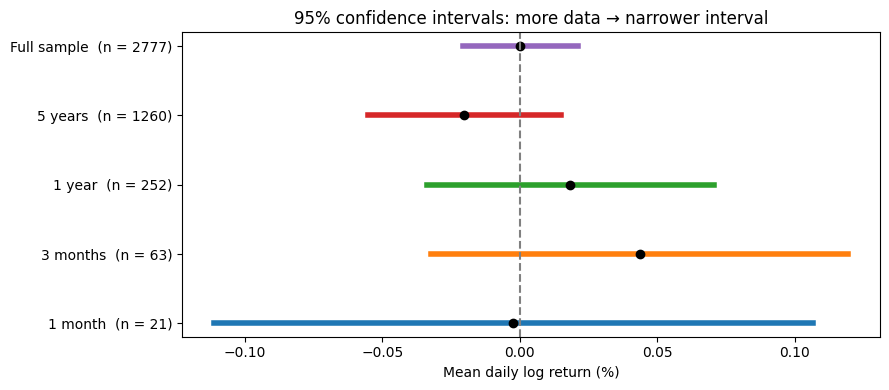

In [15]:
fig, ax = plt.subplots(figsize=(9, 4))                 # create a blank chart
for i, row in table.iterrows():                        # one line per window
    ax.plot([row["Lower"], row["Upper"]], [i, i], lw=4)   # draw the interval
    ax.plot(row["x̄"], i, "ko")                            # mark the sample mean
ax.axvline(0, color="grey", ls="--")                   # dashed line at zero
ax.set_yticks(range(len(table)))                       # one tick per window
ax.set_yticklabels(table["Window"] + "  (n = " + table["n"].astype(str) + ")")
ax.set_xlabel("Mean daily log return (%)")
ax.set_title("95% confidence intervals: more data → narrower interval")
plt.tight_layout()
plt.show()
# Bigger n → smaller standard error → narrower interval.

**Interpretation:** As the sample size grows from 21 days to 2,777 days, the confidence interval gets narrower, so the estimate becomes more precise. Every interval still contains 0, so at no horizon can we say the average gilt return differs from zero.